# Milestone 3 · Notebook 2: End-to-End Pipeline Check

**Project:** Deepfake Voice Detection for Indian Languages · Group-3

This notebook runs our complete workflow once, on a small subset of the data, to show that every part works
together: load the preprocessed clips, build the model, train it, score new clips and evaluate the scores.

**The subset** (3,018 clips) comes from `01_data_preparation.ipynb`. Every clip there has already been converted to
16 kHz mono, trimmed of edge silence and set to −20 dBFS, and assigned to a split so that no speaker is in two
splits.

**The model** is the pretrained speech encoder XLS-R 300M with a small classification head, as chosen in Milestone 1.

| Section | What it does |
| --- | --- |
| 1. Setup and data | Loads the subset and shows what's in each split |
| 2. Before and after preprocessing | One real and one fake clip, as stored in the source and after preprocessing |
| 3. Model | Builds XLS-R with its head and checks the tensor shapes on one batch |
| 4. Training | One epoch with weighted cross-entropy |
| 5. Inference | Scores every clip outside the training split |
| 6. Evaluation | EER, ROC AUC, accuracy and confusion matrix per test set, and sample outputs |
| 7. Summary | What the run shows, and which Milestone-3 requirement each section answers |

**How to run:** on Kaggle with a **T4 GPU** and internet on, add the private dataset
`tarikasubhashhedaoo/dsai-group3-m3-subset` as input, then *Run All*. It takes about 5 minutes.

**One epoch on 1,492 training clips checks that the pipeline works. The results don't measure final performance.**

## 1. Setup and Data

In [1]:
import os
import random
import time
from pathlib import Path

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"  # keep the notebook output readable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from torch import nn
from torch.utils.data import DataLoader, Dataset
from transformers import Wav2Vec2Model
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()
pd.set_option("display.width", 200)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MODEL_NAME = "facebook/wav2vec2-xls-r-300m"
CLIP_SAMPLES = 4 * 16000  # every clip is cut or padded to 4 s at 16 kHz
BATCH = 8
LABELS = {"real": 0, "fake": 1}
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

Device: cuda Tesla T4


The dataset is found wherever Kaggle mounts it under `/kaggle/input`. Outside Kaggle, the notebook uses the
repository's `data/` folder.

In [2]:
found = sorted(Path("/kaggle/input").glob("**/manifests/manifest_subset.csv"))
DATA = found[0].parents[1] if found else Path.cwd().resolve().parents[1] / "data"

manifest = pd.read_csv(DATA / "manifests" / "manifest_subset.csv", keep_default_na=False)
print(f"{len(manifest)} clips from {DATA}")
SPLITS = ["train", "valid", "test_indomain", "test_unseen_gen", "test_itw", "test_asvspoof"]
pd.crosstab(manifest.split, manifest.label, margins=True, margins_name="total").reindex(SPLITS + ["total"])

3018 clips from /kaggle/input/datasets/tarikasubhashhedaoo/dsai-group3-m3-subset


label,fake,real,total
split,,,
train,746,746,1492
valid,200,197,397
test_indomain,150,150,300
test_unseen_gen,270,270,540
test_itw,96,97,193
test_asvspoof,48,48,96
total,1510,1508,3018


Every split is balanced between real and fake. What each split is for:

| Split | Contents | Used for |
| --- | --- | --- |
| `train` | Kathbath (real) + IndicSynth (fake) in Hindi, Tamil, Telugu; ASVspoof 2019 LA train (English) | Training |
| `valid` | The same sources, with other speakers; ASVspoof dev | Choosing the decision threshold |
| `test_indomain` | The same sources, with other speakers again | Test: new speakers, known generators |
| `test_unseen_gen` | Our generated set (Indic Parler-TTS, IndicF5, MMS-TTS) + Kathbath test speakers reading the same sentences | Test: generators never seen in training |
| `test_itw` | In-the-Wild (English) | Test: real-world audio |
| `test_asvspoof` | ASVspoof 2019 LA eval (English, attacks A07–A19) | Test: unseen English attacks |

## 2. Before and After Preprocessing

One real clip (Kathbath, Hindi) and one fake clip (IndicSynth XTTS-v2, Hindi), as stored in the source
(`raw_path`) and after preprocessing (`path`).

/usr/local/lib/python3.13/dist-packages/matplotlib/axes/_axes.py:8233: RuntimeWarning: divide by zero encountered in log10
  Z = 10. * np.log10(spec)


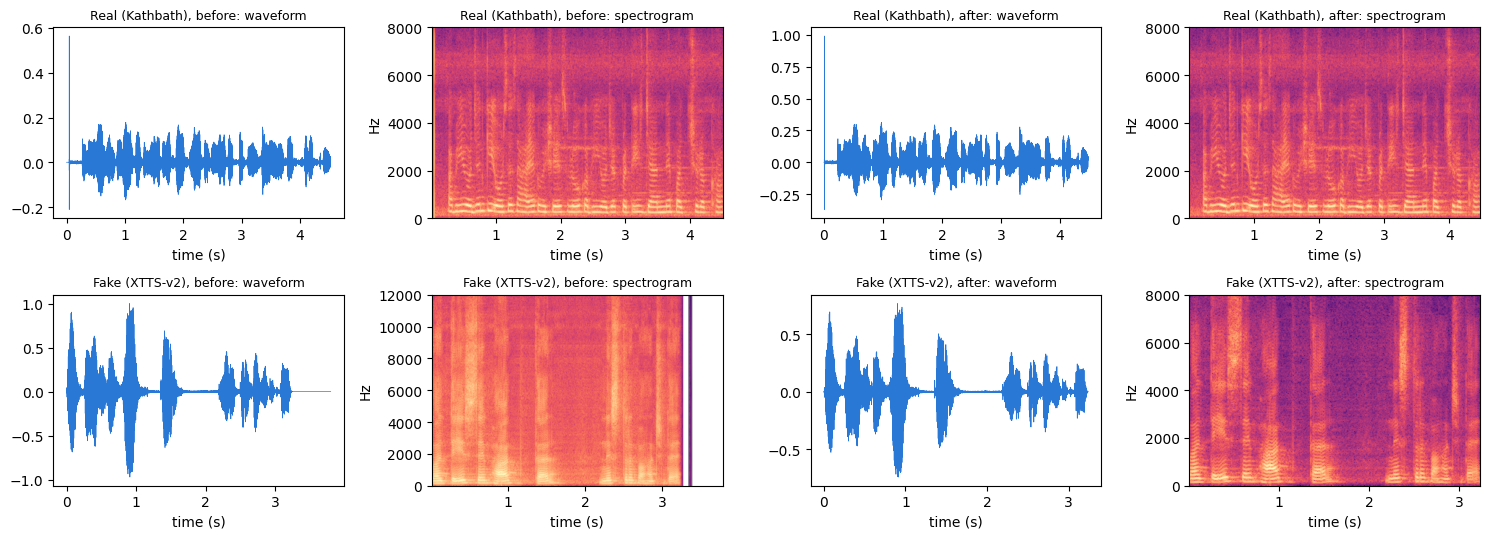

,clip,stage,sample rate (Hz),duration (s),RMS (dBFS),peak
0,Real (Kathbath),before,16000,4.53,-28.0,0.56
1,Real (Kathbath),after,16000,4.48,-23.0,0.99
2,Fake (XTTS-v2),before,24000,3.80,-18.4,1.00
3,Fake (XTTS-v2),after,16000,3.24,-20.0,0.77


In [3]:
examples = {
    "Real (Kathbath)": manifest[(manifest.dataset == "kathbath") & (manifest.language == "hi")
                                & (manifest.split == "test_indomain")].iloc[0],
    "Fake (XTTS-v2)": manifest[(manifest.generator == "xtts_v2") & (manifest.language == "hi")
                               & (manifest.split == "test_indomain")].iloc[0],
}

rows = []
fig, axes = plt.subplots(2, 4, figsize=(15, 5.5))
for r, (name, clip) in enumerate(examples.items()):
    for c, (stage, path) in enumerate([("before", clip.raw_path), ("after", clip.path)]):
        audio, sr = sf.read(DATA / path, dtype="float32", always_2d=True)
        audio = audio.mean(axis=1)
        rows.append({"clip": name, "stage": stage, "sample rate (Hz)": sr, "duration (s)": round(len(audio) / sr, 2),
                     "RMS (dBFS)": round(20 * np.log10(np.sqrt(np.mean(audio ** 2))), 1),
                     "peak": round(float(np.abs(audio).max()), 2)})
        wave_ax, spec_ax = axes[r, 2 * c], axes[r, 2 * c + 1]
        wave_ax.plot(np.arange(len(audio)) / sr, audio, linewidth=0.5, color="#2a78d6")
        wave_ax.set_title(f"{name}, {stage}: waveform", fontsize=9)
        spec_ax.specgram(audio, NFFT=512, Fs=sr, noverlap=384, cmap="magma")
        spec_ax.set_title(f"{name}, {stage}: spectrogram", fontsize=9)
        spec_ax.set_ylabel("Hz")
        for ax in (wave_ax, spec_ax):
            ax.set_xlabel("time (s)")
fig.tight_layout()
fig.savefig("before_after_preprocessing.png", dpi=130)
plt.show()
pd.DataFrame(rows)

**What changed:**

- **Sample rate:** the fake clip was 24 kHz and the real one 16 kHz. A model could have told them apart by that
  alone, one of the shortcuts found in Milestone 2. Both are now 16 kHz.
- **Silence:** the silence at the start and end of each clip is cut.
- **Loudness:** it's raised or lowered to −20 dBFS, unless a loud peak would then go past 0.99. In that case it
  stops at the peak limit, which is why a clip can end slightly quieter than −20 dBFS (see the table).

## 3. Model

| Step | Output shape |
| --- | --- |
| Input: a clip cut or zero-padded to 4 s, scaled to zero mean and unit variance | `[B, 64000]` |
| XLS-R CNN feature encoder (pretrained, frozen): one frame every 20 ms | `[B, 199, 512]` |
| XLS-R transformer, 24 layers (pretrained, fine-tuned) | `[B, 199, 1024]` |
| Average over the frames that hold audio | `[B, 1024]` |
| Head: Dropout(0.1) → Linear(1024, 2) (new) | `[B, 2]` |
| Softmax | `p_fake`: the probability that the clip is fake |

`B` is the number of clips in a batch. The scaling copies what XLS-R's own feature extractor does
(`do_normalize=True`). Padded clips get an attention mask, so the padding is ignored.

In [4]:
class ClipDataset(Dataset):
    """Returns (waveform, attention mask, label, clip id) for each clip in `rows`."""

    def __init__(self, rows, train):
        self.rows, self.train = rows.reset_index(drop=True), train

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        row = self.rows.iloc[i]
        audio, _ = sf.read(DATA / row.path, dtype="float32")
        if len(audio) > CLIP_SAMPLES:  # random 4 s in training, the middle 4 s otherwise
            start = random.randint(0, len(audio) - CLIP_SAMPLES) if self.train else (len(audio) - CLIP_SAMPLES) // 2
            audio = audio[start:start + CLIP_SAMPLES]
        audio = (audio - audio.mean()) / (audio.std() + 1e-7)
        wave, mask = np.zeros(CLIP_SAMPLES, np.float32), np.zeros(CLIP_SAMPLES, np.int64)
        wave[:len(audio)], mask[:len(audio)] = audio, 1  # shorter clips are zero-padded
        return torch.from_numpy(wave), torch.from_numpy(mask), LABELS[row.label], row.clip_id


class Detector(nn.Module):
    """XLS-R encoder + mean pooling + linear head."""

    def __init__(self):
        super().__init__()
        self.encoder = Wav2Vec2Model.from_pretrained(MODEL_NAME)
        self.encoder.freeze_feature_encoder()
        self.head = nn.Sequential(nn.Dropout(0.1), nn.Linear(self.encoder.config.hidden_size, 2))

    def forward(self, wave, mask, show_shapes=False):
        frames = self.encoder(wave, attention_mask=mask).last_hidden_state
        # which frames hold audio (not padding); a helper from the transformers library
        frame_mask = self.encoder._get_feature_vector_attention_mask(frames.shape[1], mask)
        pooled = (frames * frame_mask[..., None]).sum(1) / frame_mask.sum(1, keepdim=True)
        logits = self.head(pooled)
        if show_shapes:
            for name, x in [("input", wave), ("XLS-R frames", frames), ("pooled", pooled), ("logits", logits)]:
                print(f"{name:13s} {tuple(x.shape)}")
        return logits


model = Detector().to(DEVICE)
n_total = sum(p.numel() for p in model.parameters())
n_trained = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Parameters: {n_total / 1e6:.1f} M in total, {n_trained / 1e6:.1f} M trained")

Parameters: 315.4 M in total, 311.2 M trained


One batch of training clips goes through the model, to check the shapes:

In [5]:
train_rows = manifest[manifest.split == "train"]
train_loader = DataLoader(ClipDataset(train_rows, train=True), batch_size=BATCH, shuffle=True, num_workers=2,
                          generator=torch.Generator().manual_seed(SEED))
wave, mask, label, _ = next(iter(train_loader))
model.eval()
with torch.no_grad():
    model(wave.to(DEVICE), mask.to(DEVICE), show_shapes=True)

input         (8, 64000)
XLS-R frames  (8, 199, 1024)
pooled        (8, 1024)
logits        (8, 2)


## 4. Training (One Epoch)

- **Loss:** cross-entropy, with class weights from the `train` counts only.
- **Optimiser:** AdamW. XLS-R learns slowly (1e-5), so its pretrained knowledge is kept; the new head learns
  faster (1e-3).
- **Batch** of 8 clips, mixed precision (fp16) to save GPU memory, seed 42.
- **No augmentation in this run.** Vikram's augmentation (noise, shift, speed, pitch, reverberation) is
  planned for full training in Milestone 4.

In [6]:
counts = train_rows.label.value_counts()
class_weights = torch.tensor([len(train_rows) / (2 * counts[name]) for name in LABELS], dtype=torch.float32)
print("Train clips:", counts.to_dict(), "| class weights (real, fake):", class_weights.numpy().round(3))

loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(DEVICE))
optimizer = torch.optim.AdamW([{"params": model.encoder.parameters(), "lr": 1e-5},
                               {"params": model.head.parameters(), "lr": 1e-3}])
scaler = torch.amp.GradScaler(enabled=DEVICE == "cuda")

model.train()
log, start = [], time.time()
for step, (wave, mask, label, _) in enumerate(train_loader, 1):
    wave, mask, label = wave.to(DEVICE), mask.to(DEVICE), label.to(DEVICE)
    with torch.autocast(DEVICE, dtype=torch.float16, enabled=DEVICE == "cuda"):
        loss = loss_fn(model(wave, mask), label)
    optimizer.zero_grad()
    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()
    log.append({"step": step, "loss": loss.item()})
    if step % 25 == 0 or step == len(train_loader):
        print(f"step {step:3d}/{len(train_loader)}  mean loss of the last 25 steps: "
              f"{np.mean([r['loss'] for r in log[-25:]]):.3f}  ({time.time() - start:.0f} s)")

train_log = pd.DataFrame(log)
train_log.to_csv("train_log.csv", index=False)
torch.save(model.state_dict(), "detector_1epoch.pt")
print(f"Training time: {(time.time() - start) / 60:.1f} min")

Train clips: {'fake': 746, 'real': 746} | class weights (real, fake): [1. 1.]
step  25/187  mean loss of the last 25 steps: 0.701  (28 s)
step  50/187  mean loss of the last 25 steps: 0.687  (53 s)
step  75/187  mean loss of the last 25 steps: 0.677  (77 s)
step 100/187  mean loss of the last 25 steps: 0.675  (101 s)
step 125/187  mean loss of the last 25 steps: 0.656  (124 s)
step 150/187  mean loss of the last 25 steps: 0.672  (148 s)
step 175/187  mean loss of the last 25 steps: 0.635  (169 s)
step 187/187  mean loss of the last 25 steps: 0.610  (180 s)
Training time: 3.0 min


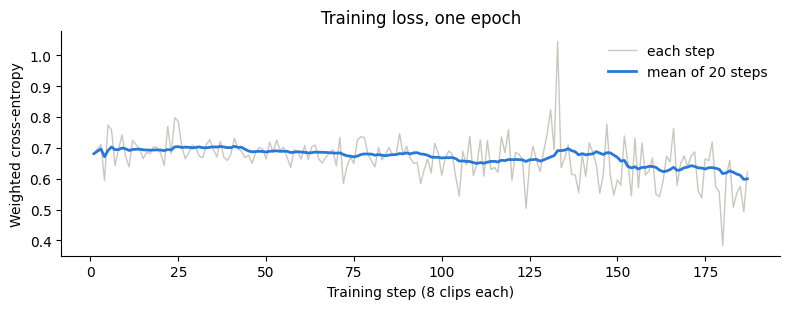

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(train_log.step, train_log.loss, color="#c9c7bf", linewidth=1, label="each step")
ax.plot(train_log.step, train_log.loss.rolling(20, min_periods=1).mean(), color="#2a78d6", linewidth=2,
        label="mean of 20 steps")
ax.set_xlabel("Training step (8 clips each)")
ax.set_ylabel("Weighted cross-entropy")
ax.set_title("Training loss, one epoch")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("training_loss.png", dpi=150)
plt.show()

## 5. Inference

Every clip outside `train` is scored, using its middle 4 s. In evaluation mode the model has no dropout and no
masking, so the same clip always gets the same score.

In [8]:
eval_rows = manifest[manifest.split != "train"]
eval_loader = DataLoader(ClipDataset(eval_rows, train=False), batch_size=16, num_workers=2)

model.eval()
scores, ids, start = [], [], time.time()
with torch.no_grad(), torch.autocast(DEVICE, dtype=torch.float16, enabled=DEVICE == "cuda"):
    for wave, mask, _, clip_id in eval_loader:
        logits = model(wave.to(DEVICE), mask.to(DEVICE)).float()
        scores += torch.softmax(logits, dim=1)[:, 1].cpu().tolist()
        ids += list(clip_id)

predictions = eval_rows.set_index("clip_id").loc[ids, ["split", "dataset", "language", "generator", "label"]]
predictions["p_fake"] = np.round(scores, 5)
predictions = predictions.reset_index()
predictions.to_csv("predictions.csv", index=False)
print(f"Scored {len(predictions)} clips in {time.time() - start:.0f} s")
predictions.head()

Scored 1526 clips in 174 s


,clip_id,split,dataset,language,generator,label,p_fake
0,asvspoof_LA_D_1047731,valid,asvspoof2019_la,en,none,real,0.32515
1,asvspoof_LA_D_1105538,valid,asvspoof2019_la,en,none,real,0.31358
2,asvspoof_LA_D_1125976,valid,asvspoof2019_la,en,none,real,0.35965
3,asvspoof_LA_D_1293230,valid,asvspoof2019_la,en,none,real,0.34362
4,asvspoof_LA_D_1340209,valid,asvspoof2019_la,en,none,real,0.35835


## 6. Evaluation

The **training loss** (Section 4) is what the model minimises. The **evaluation metrics** are how we judge it:

| Metric | What it measures |
| --- | --- |
| **EER** (main metric) | The error rate at the threshold where fakes accepted as real equal real clips rejected as fake. It doesn't depend on a chosen threshold, and it's the standard measure in ASVspoof work (Milestone 1) |
| **ROC AUC** | How well `p_fake` ranks fake clips above real ones (0.5 = chance, 1 = perfect) |
| **Accuracy and confusion matrix** | Results at one fixed threshold: the one where `valid` reaches its EER. It's chosen on `valid` only and then used unchanged on every test split |

In [9]:
def eer(is_fake, scores):
    """Equal error rate, and the threshold where it's reached."""
    fpr, tpr, thresholds = roc_curve(is_fake, scores)
    i = np.nanargmin(np.abs((1 - tpr) - fpr))
    return (fpr[i] + 1 - tpr[i]) / 2, thresholds[i]


valid = predictions[predictions.split == "valid"]
_, THRESHOLD = eer(valid.label == "fake", valid.p_fake)
predictions["predicted"] = np.where(predictions.p_fake >= THRESHOLD, "fake", "real")
print(f"Decision threshold, chosen on valid: a clip is called fake when p_fake >= {THRESHOLD:.3f}")

results = []
for split in SPLITS[1:]:
    part = predictions[predictions.split == split]
    tn, fp, fn, tp = confusion_matrix(part.label, part.predicted, labels=["real", "fake"]).ravel()
    results.append({"split": split, "clips": len(part),
                    "EER (%)": round(100 * eer(part.label == "fake", part.p_fake)[0], 1),
                    "ROC AUC": round(roc_auc_score(part.label == "fake", part.p_fake), 3),
                    "accuracy": round((part.predicted == part.label).mean(), 3),
                    "real → real": tn, "real → fake": fp, "fake → real": fn, "fake → fake": tp})
results = pd.DataFrame(results)
results.to_csv("results.csv", index=False)
results

Decision threshold, chosen on valid: a clip is called fake when p_fake >= 0.316


,split,clips,EER (%),ROC AUC,accuracy,real → real,real → fake,fake → real,fake → fake
0,valid,397,24.4,0.863,0.756,149,48,49,151
1,test_indomain,300,17.7,0.924,0.780,142,8,58,92
2,test_unseen_gen,540,20.6,0.854,0.743,251,19,120,150
3,test_itw,193,31.6,0.735,0.658,89,8,58,38
4,test_asvspoof,96,33.3,0.763,0.500,0,48,0,48


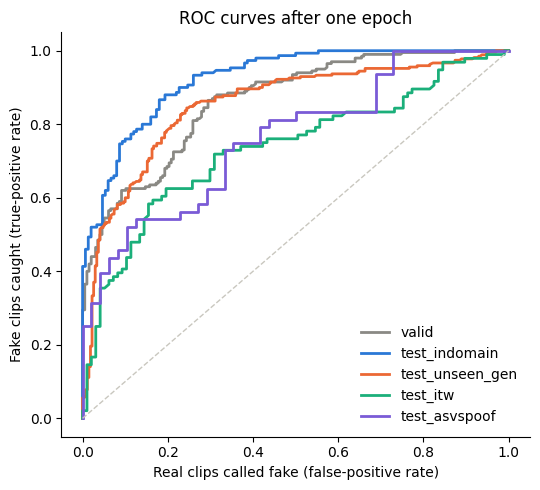

In [10]:
fig, ax = plt.subplots(figsize=(5.5, 5))
colors = {"valid": "#8a8984", "test_indomain": "#2a78d6", "test_unseen_gen": "#eb6834",
          "test_itw": "#1baf7a", "test_asvspoof": "#7a5bd6"}
for split, color in colors.items():
    part = predictions[predictions.split == split]
    fpr, tpr, _ = roc_curve(part.label == "fake", part.p_fake)
    ax.plot(fpr, tpr, color=color, linewidth=2, label=split)
ax.plot([0, 1], [0, 1], color="#c9c7bf", linestyle="--", linewidth=1)
ax.set_xlabel("Real clips called fake (false-positive rate)")
ax.set_ylabel("Fake clips caught (true-positive rate)")
ax.set_title("ROC curves after one epoch")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("roc_curves.png", dpi=150)
plt.show()

**Unseen generators:** the share of each new generator's fakes that are caught at the threshold, per language.

In [11]:
unseen_fakes = predictions[(predictions.split == "test_unseen_gen") & (predictions.label == "fake")]
unseen_fakes.assign(caught=unseen_fakes.predicted == "fake").pivot_table(
    index="generator", columns="language", values="caught", aggfunc="mean", margins=True, margins_name="all").round(3)

language,hi,ta,te,all
generator,,,,
indic-parler-tts,1.000,0.767,0.933,0.900
indicf5,0.300,0.133,0.367,0.267
mms-tts,0.967,0.533,0.000,0.500
all,0.756,0.478,0.433,0.556


**Sample outputs:** one real and one fake clip from each test split, chosen at random (seed 42). The confidence is
the model's probability for the label it predicts.

In [12]:
samples = predictions[predictions.split != "valid"].groupby(["split", "label"]).sample(1, random_state=SEED)
samples["confidence"] = np.where(samples.predicted == "fake", samples.p_fake, 1 - samples.p_fake).round(3)
samples["correct"] = np.where(samples.predicted == samples.label, "yes", "no")
samples[["clip_id", "split", "language", "generator", "label", "predicted", "p_fake", "confidence", "correct"]]

,clip_id,split,language,generator,label,predicted,p_fake,confidence,correct
1472,asvspoof_LA_E_4945590,test_asvspoof,en,A10,fake,fake,0.34881,0.349,yes
1513,asvspoof_LA_E_9034056,test_asvspoof,en,none,real,fake,0.39762,0.398,no
526,indicsynth_te_xtts_v2____1195-m-722,test_indomain,te,xtts_v2,fake,real,0.30939,0.691,no
551,kathbath_hi_844424930731870-1148-f,test_indomain,hi,none,real,real,0.24203,0.758,yes
1387,itw_31576,test_itw,en,unknown_tts,fake,fake,0.38168,0.382,yes
1238,itw_10118,test_itw,en,none,real,real,0.26617,0.734,yes
943,te_0513_mms-tts,test_unseen_gen,te,mms-tts,fake,real,0.28304,0.717,no
1198,kathbath_te_844424932737198-944-f,test_unseen_gen,te,none,real,real,0.26412,0.736,yes


## 7. Summary

**The pipeline works end to end.** On a Kaggle T4 the notebook loaded the 3,018-clip subset, built XLS-R 300M with
its head (315.4 M parameters), trained it for one epoch (187 steps, 3.0 min) and scored all 1,526 validation and
test clips (174 s). The training loss fell from 0.701 to 0.610 (mean of the first and last 25 steps).

**Results after one epoch** (Section 6), with the decision threshold chosen on `valid` (`p_fake` ≥ 0.316):

| Split | EER | ROC AUC | What it tests |
| --- | ---: | ---: | --- |
| `test_indomain` | 17.7% | 0.924 | New speakers, known generators |
| `test_unseen_gen` | 20.6% | 0.854 | Generators never seen in training |
| `test_itw` | 31.6% | 0.735 | Real-world English audio |
| `test_asvspoof` | 33.3% | 0.763 | Unseen English attacks |

What the outputs show:

- The model already ranks fakes above real clips on every test split (AUC 0.735–0.924), so it learns from the data.
  It is best on known generators and new speakers, and weakest on real-world English.
- **Unseen generators differ a lot:** 90.0% of Indic Parler-TTS fakes are caught, 50.0% of MMS-TTS, and only 26.7%
  of IndicF5. IndicF5 clones real voices, which makes it the hardest of the three.
- **ASVspoof eval:** at the validation threshold every clip is called fake (accuracy 0.500). The scores still rank
  most fakes above real clips (AUC 0.763), but the threshold set on `valid` doesn't carry over to this source.
- After one epoch the scores sit close together: every `p_fake` is between 0.20 and 0.65, and half are below 0.30.
  So a correct "fake" verdict can still come with a `p_fake` below 0.5, and the confidence values are low.

**These results check the pipeline; they don't measure final performance.** Full training (more data, more epochs,
augmentation) comes in Milestone 4.

**Milestone-3 requirements answered in this notebook:**

| Requirement | Where |
| --- | --- |
| A sample before and after preprocessing | Section 2 |
| Model components, input shapes and output format | Section 3 |
| How the processed data matches the model's input | Sections 2 and 3 |
| A small training run (one epoch), then inference and evaluation | Sections 4, 5 and 6 |
| Sample inputs alongside their outputs and expected outputs | Section 6, sample outputs |
| Loss function, evaluation metrics and preliminary results | Sections 4 and 6 |
| Number of samples used and how they were chosen | Section 1 (chosen in `01_data_preparation.ipynb`) |
